5. Statistical Analysis

In EDA we saw that provincial capitals have almost twice as many accidents per inhabitant as other municipalities (4.29 vs 2.20), but less than half the severity (1.06 vs 2.53 deaths per 100 accidents).

The question is: are this differences statistically significant or are due to random chance?

5.1 Hypothesis Test

Let's use the Hypothesis Testing to answer this question.

Test 1) H0 (null hypothesis): provincial capitals and other municipalities have the same % of accidents;	H1 (alternative hypothesis): provincial capitals have a higher % of accidents than other municipalities.

Test 2) H0 (null hypothesis): provincial capitals and other municipalities have the same "deaths per 100 accidents"; H1 (alternative hypothesis): provincial capitals have a lower "deaths per 100 accidents" than other municipalities.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu

PROCESSED_DIR = Path("../data/processed")
FIGURES_DIR = Path("../reports/figures")
ALPHA = 0.05

sns.set_theme(style="whitegrid")


def save_figure(fig, name):
    """Save a figure in reports/figures for the presentation."""
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


df_mun = pd.read_csv(PROCESSED_DIR / "municipalities_clusters.csv",
                     dtype={"REF_AREA": str, "COD_REG": str},
                     keep_default_na=False, na_values=[""])
df_mun["is_provincial_capital"] = df_mun["CC_UTS"].astype(int) == 1

df_test = df_mun[df_mun["above_threshold"]].copy()
print(df_test["is_provincial_capital"].value_counts())

is_provincial_capital
False    2071
True      109
Name: count, dtype: int64


Alpha is the conventional threshold for rejecting the null hypothesis. If the p-value is less than alpha, we reject the null hypothesis.

In [14]:
def compare_groups(df, column, alternative):
    """Mann-Whitney U test between provincial capitals and other municipalities."""
    capitals = df.loc[df["is_provincial_capital"], column]
    others = df.loc[~df["is_provincial_capital"], column]

    result = mannwhitneyu(capitals, others, alternative=alternative)

    return pd.Series({
        "n_capitals": len(capitals),
        "n_others": len(others),
        "U": result.statistic,
        "p_value": result.pvalue,
    })


results = pd.DataFrame({
    "Accident rate (H1: capitals higher)": compare_groups(df_test, "accidents_per_1000_inh", "greater"),
    "Severity (H1: capitals lower)": compare_groups(df_test, "deaths_per_100_accidents", "less"),
}).T

results["significant"] = results["p_value"] < ALPHA
print(f"Significance threshold: {ALPHA}")
results.round(4)

Significance threshold: 0.05


,n_capitals,n_others,U,p_value,significant
Accident rate (H1: capitals higher),109.0,2071.0,176618.0,0.0000,True
Severity (H1: capitals lower),109.0,2071.0,95742.5,0.0033,True


Analysis:
1) We used the Mann-Whitney U test instead the t-test beacause it doesn't require a particular distribution of data; t-test needs a normal distribution and it's heavily influenced by outliers. To use the t-test, we need to convert the data in a logarithmic scale.
2) We didn't use any permutation because we already knew the distribution shape (bell shape).
3) Both p-values are really lower then alpha value, so we reject both null hypothesis.
4) We used one-sided tests, because we saw the direction of the tail in the EDA analysis; in any case, two-sided tests lead to the same conclusions.
5) Provincial capitals have a significantly higher accident rate than other municipalities (p < 0.0001); they also have significantly lower severity (p = 0.0033)
6) The difference in deaths per 100 accidents is strong in the aggregate data but weak at the municipality level, because the indicator is unstable for individual municipalities (too many municipalities with 0 or 1 accidents)

Conclusions:

Provincial capitals are the areas where accidents are most frequent, and therefore the natural place for interventions aimed at reducing the number of accidents; interventions aimed at reducing their deaths should instead be sought outside cities, on extra-urban roads.

5.2 Regression

The regression answers a different question from the hypothesis test. The test showed that provincial capitals have more accidents; but capitals are also more densely populated, larger, and distributed differently between North and South. Which of these factors really matters, all else being equal? The regression considers them all together and estimates the effect of each one.

 It gaives us another information: once the model knows how many accidents to expect from a municipality with given characteristics, we can identify the municipalities that have way more accidents than expected. These are the places where the risk is not explained by density or size, but by something specific to the area.
 They are ideal candidates for inspection and investment.

In [23]:
import statsmodels.formula.api as smf

In [25]:
AREA_NAMES = {1: "North-West", 2: "North-East", 3: "Centre", 4: "South", 5: "Islands"}
df_mun["macro_area"] = df_mun["COD_RIP"].astype(int).map(AREA_NAMES)

MIN_POPULATION = 5000
df_reg = df_mun[df_mun["POP_RES"] >= MIN_POPULATION].copy()

df_reg["log_rate"] = np.log1p(df_reg["accidents_per_1000_inh"])
df_reg["log_density"] = np.log(df_reg["POP_RES"] / df_reg["AREA_KMQ"])
df_reg["log_population"] = np.log(df_reg["POP_RES"])
df_reg["capital"] = df_reg["is_provincial_capital"].astype(int)

print("Municipalities in the regression:", len(df_reg))


Municipalities in the regression: 2376


We used population per km^2 because it's indipendent from accidents; we, also, used municipalities with more than 5.000 people instead per number of accidents for the same reason.

In [43]:
model = smf.ols(
    "log_rate ~ log_density + log_population + capital"
    " + C(macro_area, Treatment('North-West'))",
    data=df_reg,
).fit(cov_type="HC3")

print(model.summary().tables[0])

                            OLS Regression Results                            
Dep. Variable:               log_rate   R-squared:                       0.287
Model:                            OLS   Adj. R-squared:                  0.285
Method:                 Least Squares   F-statistic:                     153.5
Date:                Wed, 14 Oct 2026   Prob (F-statistic):          2.98e-187
Time:                        16:00:58   Log-Likelihood:                -562.12
No. Observations:                2376   AIC:                             1140.
Df Residuals:                    2368   BIC:                             1186.
Df Model:                           7                                         
Covariance Type:                  HC3                                         


smf.ols --> linear regression with ordinary least squares.

C transform the variable in a number (0 or 1); Treatment choose a reference category (in this case "North-West").

cov_type="HC3" calculate strong standard errors; classic regression assumes that the variability of the errors is the same for all municipalities (homoscedasticity). With our data this is unlikely.

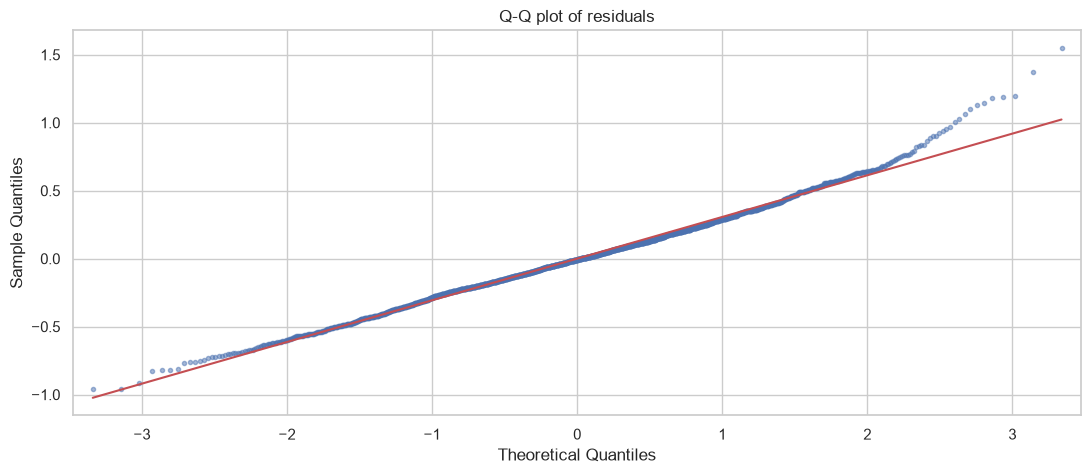

In [40]:
fig, ax = plt.subplots(figsize=(13, 5))

sm_qq = __import__("statsmodels.api", fromlist=["qqplot"]).qqplot
sm_qq(model.resid, line="s", ax=ax, markersize=3, alpha=0.5)
ax.set_title("Q-Q plot of residuals")

save_figure(fig, "11_regression_diagnostics")
plt.show()

The Q-Q plot compares the residual distribution with a normal distribution. If the points follow the red line, residual are nearly normal.

Because we have outliers, it's normal to see the points at the edges that are away from the red line. 

In [35]:
df_reg["expected_rate"] = np.expm1(model.fittedvalues)
df_reg["excess_ratio"] = df_reg["accidents_per_1000_inh"] / df_reg["expected_rate"]

cols = ["COMUNE", "SIGLA_AUTOMOBILISTICA", "POP_RES", "accidents_per_1000_inh",
        "expected_rate", "excess_ratio", "cluster_name"]
df_reg.nlargest(15, "excess_ratio")[cols].round(2)

,COMUNE,SIGLA_AUTOMOBILISTICA,POP_RES,accidents_per_1000_inh,expected_rate,excess_ratio,cluster_name
4170,Forte dei Marmi,LU,6777,13.43,2.06,6.52,Dense urban areas
3836,Bentivoglio,BO,5777,11.08,2.07,5.36,High accident rate
5335,Maiori,SA,5311,5.93,1.20,4.95,High accident rate
6062,Porto Cesareo,LE,6463,6.11,1.29,4.72,High accident rate
1706,Assago,MI,9224,8.35,1.83,4.57,Dense urban areas
1294,Santa Margherita Ligure,GE,8437,8.12,1.79,4.53,Dense urban areas
3535,Lignano Sabbiadoro,UD,6901,9.20,2.11,4.37,Dense urban areas
1174,Albissola Marina,SV,5153,6.60,1.54,4.30,Dense urban areas
5426,Vietri sul Mare,SA,7080,5.23,1.29,4.06,Dense urban areas
1268,Lavagna,GE,12342,7.66,1.99,3.86,Dense urban areas


np.expm1 converts the model's predicted values back to the original scale (accidents per 1,000 inhabitants), and excess_ratio is the ratio between the observed and the expected rate: a value of 2 means that the municipality has twice as many accidents as the model would expect from a municipality with its characteristics. 

The municipalities at the top are those where the risk is not explained by density, size, capital status or geographical area: something specific is going on, which deserves an on-site investigation and potentially an investment.

Conclusions:

1. The model explains about 29% of the variation in accident rates between municipalities (R² = 0.287). It's not a model problem, it's an evidence that most of the differences depends on factors that we don't have (like traffic, streets, tourism, ecc).
2. All other things being equal, provincial capitals and more populous municipalities have higher accidents rates; the Centre and the North-East have higher rates than the North-West, while the South and the Islands have lower ones.
3. Population density has no significant effect once population size is taken into account.
4. The residuals are approximately normal, with a heavy right tail caused by municipalities with a large excess of accidents.
5. The municipalities with the largest excess are almost all coastal tourist resorts, especially in Liguria: tourism is the main missing variable of the model.
6. There is also Bentivoglio, near Bologna, that hosts a major freight logistics hub with heavy goods vehicle traffic; Assago is a shopping and events hub next to Milan's ring roads. The mechanism is the same: many people and vehicles circulating in the municipality without living there.


In [44]:
df_final = df_mun.drop(columns=["expected_rate", "excess_ratio"], errors="ignore").merge(
    df_reg[["REF_AREA", "expected_rate", "excess_ratio"]], on="REF_AREA", how="left"
)
df_final.to_csv(PROCESSED_DIR / "municipalities_final.csv", index=False)
print(df_final.shape)

(7900, 24)


In [46]:
REGION_NAMES = {
    "01": "Piemonte", "02": "Valle d'Aosta", "03": "Lombardia",
    "04": "Trentino-Alto Adige", "05": "Veneto", "06": "Friuli-Venezia Giulia",
    "07": "Liguria", "08": "Emilia-Romagna", "09": "Toscana", "10": "Umbria",
    "11": "Marche", "12": "Lazio", "13": "Abruzzo", "14": "Molise",
    "15": "Campania", "16": "Puglia", "17": "Basilicata", "18": "Calabria",
    "19": "Sicilia", "20": "Sardegna",
}
df_final["region"] = df_final["COD_REG"].map(REGION_NAMES)
df_final["location"] = (
    df_final["COMUNE"] + ", " + df_final["SIGLA_AUTOMOBILISTICA"] + ", Italy"
)
print("Missing regions:", df_final["region"].isna().sum())
df_final.to_csv(PROCESSED_DIR / "municipalities_final.csv", index=False)

df_accidents = pd.read_csv(PROCESSED_DIR / "municipalities_accidents.csv", dtype={"REF_AREA": str})
national = df_accidents.groupby("TIME_PERIOD", as_index=False)[["accidents", "injured", "deaths"]].sum()
national.to_csv(PROCESSED_DIR / "national_trend.csv", index=False)

Missing regions: 0
